In [1]:
import numpy as np 
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense ,Conv2D,MaxPool2D,Flatten

from tensorflow.keras.utils import to_categorical


In [ ]:
df=np.load(r"mnist.npz")

In [3]:
x_train =df['x_train']
x_test =df['x_test']
y_train =df['y_train']
y_test =df['y_test']

In [4]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


classes: [0 1 2 3 4 5 6 7 8 9]


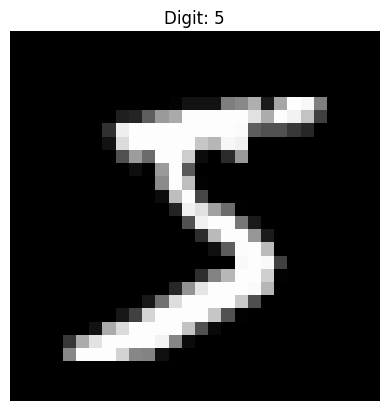

In [5]:
print("classes:",np.unique(y_train))

plt.imshow(x_train[0],cmap='gray')
plt.title("Digit: "+ str(y_train[0]))
plt.axis('off')
plt.show()




In [6]:
#normalize the image
x_train=x_train.astype('float32')
x_test = x_test.astype('float32')

In [7]:
#prepare of DNN

x_train_dnn = x_train.reshape(60000,784)
x_test_dnn = x_test.reshape(10000,784)

In [8]:
y_train_cat =to_categorical(y_train ,10)
y_test_cat =to_categorical(y_test ,10)

In [9]:
#dnn model building 

dnn= Sequential([
    Flatten(input_shape=(784,)),
    Dense(128,activation='relu'),
    Dense(64,activation = 'relu'),
    Dense(10 , activation= 'softmax'),
    
])

dnn.summary()

C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#compile
dnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history_dnn =dnn.fit(
    x_train_dnn,y_train,
    epochs =10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9492 - loss: 0.2927 - val_accuracy: 0.9404 - val_loss: 0.3820
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9599 - loss: 0.2009 - val_accuracy: 0.9468 - val_loss: 0.3457
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9669 - loss: 0.1502 - val_accuracy: 0.9441 - val_loss: 0.3261
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9717 - loss: 0.1134 - val_accuracy: 0.9584 - val_loss: 0.2516
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9760 - loss: 0.0997 - val_accuracy: 0.9555 - val_loss: 0.2635
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9770 - loss: 0.0921 - val_accuracy: 0.9558 - val_loss: 0.2542
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9786 - loss: 0.0788 - val_accuracy: 0.9563 - val_loss: 0.2558
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9799 - loss: 0.0820 - val_accuracy: 0

In [14]:
loss_dnn , accuracy_dnn = dnn.evaluate(x_test_dnn,y_test,verbose = 0)

In [17]:
print("dnn test loss: ",loss_dnn)
print("dnnn test accuracy",accuracy_dnn*100, "%")

dnn test loss:  0.24357815086841583
dnnn test accuracy 96.069997549057 %


In [22]:
#CNN

x_train_cnn= x_train.reshape(60000,28,28,1)
x_test_cnn= x_test.reshape(10000,28,28,1)

#normalize pixel value

x_train_cnn= x_train_cnn/255.0
x_test_cnn= x_test_cnn/255.0

print(x_train_cnn.shape)
print(x_test_cnn.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [23]:
#create cnn model
cnn=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPool2D((2,2)),
    Flatten(),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])

cnn.summary()

C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │         346,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
##compile and train

cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn.fit(x_train_cnn,y_train,
       epochs=10,
       batch_size=128,
       validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9190 - loss: 0.2867 - val_accuracy: 0.9684 - val_loss: 0.1223
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9736 - loss: 0.0924 - val_accuracy: 0.9768 - val_loss: 0.0806
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9813 - loss: 0.0645 - val_accuracy: 0.9797 - val_loss: 0.0696
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9855 - loss: 0.0501 - val_accuracy: 0.9811 - val_loss: 0.0635
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9888 - loss: 0.0400 - val_accuracy: 0.9817 - val_loss: 0.0602
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9911 - loss: 0.0322 - val_accuracy: 0.9819 - val_loss: 0.0611
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9929 - loss: 0.0257 - val_accuracy: 0.9827 - val_loss: 0.0595
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9948 - loss: 0.0205 - val_accuracy: 0.

In [27]:
#evaluate
loss_cnn, accuracy_cnn = cnn.evaluate(
    x_test_cnn,y_test,verbose=0
)
print("loss: ",loss_cnn)
print("accuracy: ",accuracy_cnn*100,"%")

loss:  0.054621610790491104
accuracy:  98.40999841690063 %


In [38]:
a=(accuracy_cnn*100)
b=(accuracy_dnn*100)

if (a>b):
    print("cnn better")
else:
    print("dnn better")

cnn better
